# User Behavior Anomaly Detection for Cybersecurity
### Exploratory Data Analysis (EDA) — Login Risk and Account Takeover

**Author:** MiyukiMol  
**Target roles:** Data Scientist · Security Analytics · Threat Detection  
**Tools:** Python, pandas, NumPy, Matplotlib, Google Colab  
**Dataset:** [Login Data Set for Risk-Based Authentication (RBA)](https://www.kaggle.com/datasets/dasgroup/rba-dataset)

---

## 1 - Executive Summary

### 1-1 Business context
Authentication systems must distinguish ordinary login activity from activity that may indicate account compromise. Repeated failed logins, unusual login timing, or changes in a user's usual country or device can be useful signals for further investigation. No single signal proves that an account has been compromised.

### 1-2 Project objective
This notebook performs an initial exploratory analysis of a **10,000-row sample** from the RBA dataset. It examines data quality, login outcomes, account-takeover labels, and a small set of user-behaviour attributes.

### 1-3 Questions this notebook investigates
1. What is the structure and quality of the sample?
2. How are successful and unsuccessful logins distributed?
3. How frequent is the account-takeover label in this sample?
4. Which countries and device types appear most often?
5. What additional checks should be completed before building detection rules?

### 1-4 Scope and limitations
- The dataset contains **synthetic login events**, not verified real-world attack logs.
- This notebook reads only the first 10,000 rows to keep the initial analysis manageable; results may not represent the full dataset.
- Country or device changes are investigation signals, not proof of malicious activity.
- Findings are descriptive and do not establish causality or model performance.
- The `Is Account Takeover` column is treated as an outcome label for exploration/evaluation, not as an input feature for a future predictive model.

**Expected outcome:** a reproducible baseline that informs the next notebook on rule-based detection.

### 1-5 Notebook Structure

This notebook follows a structured exploratory data analysis workflow:

1. **Environment and Reproducibility:** Import libraries and prepare the analysis environment.
2. **Dataset Acquisition and Loading:** Download the dataset and load a 10,000-row sample.
3. **Define the Analysis Scope:** Select relevant features and prepare timestamps.
4. **Data Quality Assessment:** Check data types, missing values, duplicates, and unique values.
5. **Login Outcome Distribution:** Examine successful and unsuccessful login attempts.
6. **Account-Takeover Label Distribution:** Investigate label frequency and class imbalance.
7. **Login Activity Over Time:** Explore short-term variations in login activity.
8. **Country and Device-Type Overview:** Examine geographic and device distributions.
9. **User-Level Behaviour Check:** Summarise login frequency across users.
10. **Key Findings and Next Steps:** Summarise findings, limitations, and future work.

The final section provides dataset attribution and references.

## 2 - Environment and Reproducibility

### 2-1 Import Libraries

In [1]:
import os
import zipfile
from getpass import getpass

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3 - Dataset Acquisition and Loading

we will download the "**Login Data Set for Risk-Based Authentication**" dataset from Kaggle and load a manageable sample without extracting the entire large CSV to disk.

https://www.kaggle.com/datasets/dasgroup/rba-dataset



In [2]:
# Install the Kaggle CLI in the current Colab runtime.
%pip -q install kaggle

In [3]:
# Enter the Kaggle API token without displaying it.
# For a public portfolio, consider using Google Colab Secrets instead.
kaggle_token = getpass("Paste your Kaggle API token: ")
os.environ["KAGGLE_API_TOKEN"] = kaggle_token

Paste your Kaggle API token: ··········


In [4]:
# Download the dataset ZIP.
!kaggle datasets download -d dasgroup/rba-dataset -p /content

Dataset URL: https://www.kaggle.com/datasets/dasgroup/rba-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 1.10G/1.10G [00:30<00:00, 38.5MB/s]



In [5]:
zip_path = "/content/rba-dataset.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    csv_files = [name for name in archive.namelist() if name.lower().endswith(".csv")]
    if not csv_files:
        raise FileNotFoundError("No CSV file was found in the downloaded ZIP.")

    print("CSV file(s) found:", csv_files)

    with archive.open(csv_files[0]) as file:
        df_raw = pd.read_csv(file, nrows=10_000)

print(f"Loaded sample: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head())

CSV file(s) found: ['rba-dataset.csv']
Loaded sample: 10,000 rows × 16 columns


,index,Login Timestamp,User ID,Round-Trip Time [ms],IP Address,Country,Region,City,ASN,User Agent String,Browser Name and Version,OS Name and Version,Device Type,Login Successful,Is Attack IP,Is Account Takeover
0,0,2020-02-03 12:43:30.772,-4324475583306591935,NaN,10.0.65.171,NO,-,-,29695,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like Mac OS X) Gecko/20150101 Firefox/20.0.0.1618 (Chro...,Firefox 20.0.0.1618,iOS 13.4,mobile,False,False,False
1,1,2020-02-03 12:43:43.549,-4324475583306591935,NaN,194.87.207.6,AU,-,-,60117,"Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus Build/JRN84D) AppleWebKit/537.36 (KHTML, like Gec...",Chrome Mobile 46.0.2490,Android 4.1,mobile,False,False,False
2,2,2020-02-03 12:43:55.873,-3284137479262433373,NaN,81.167.144.58,NO,Vestland,Urangsvag,29695,"Mozilla/5.0 (iPad; CPU OS 7_1 like Mac OS X) AppleWebKit/533.1 (KHTML, like Gecko Version/4.0 M...",Android 2.3.3.2672,iOS 7.1,mobile,True,False,False
3,3,2020-02-03 12:43:56.180,-4324475583306591935,NaN,170.39.78.152,US,-,-,393398,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus Build/JRN84D) Build/OPS27.82-19-4; wv AppleWebKit...,Chrome Mobile WebView 85.0.4183,Android 4.1,mobile,False,False,False
4,4,2020-02-03 12:43:59.396,-4618854071942621186,NaN,10.0.0.47,US,Virginia,Ashburn,398986,"Mozilla/5.0 (Linux; U; Android 2.2) Build/NMA26.42-169; wv AppleWebKit/537.36 (KHTML, like Geck...",Chrome Mobile WebView 85.0.4183,Android 2.2,mobile,False,True,False


### Initial interpretation
The sample is intentionally limited to 10,000 rows so that the first EDA iteration is quick to run. The source dataset is much larger, so all conclusions in this notebook must be described as conclusions about **this sample**, not the complete dataset.

## 4 - Define the Analysis Scope

Select the fields needed for a first behavioural baseline while retaining the takeover label for later evaluation.

### 4-1 Selected columns
- `User ID`: groups events by account.
- `Login Timestamp`: supports time-based analysis.
- `Login Successful`: records the login outcome.
- `Country`: supports a basic geographic-behaviour view.
- `Device Type`: supports a basic device-behaviour view.
- `Is Account Takeover`: outcome label used for descriptive analysis and later evaluation.

`Is Account Takeover` must **not** be included as a predictor when training a model to predict account takeover. Doing so would leak the answer into the input features. The `index` column is excluded because it is generally a row identifier rather than a behavioural signal.

In [6]:
selected_columns = [
    "User ID",
    "Login Timestamp",
    "Login Successful",
    "Country",
    "Device Type",
    "Is Account Takeover",
]

missing_columns = [col for col in selected_columns if col not in df_raw.columns]
if missing_columns:
    raise KeyError(f"Expected columns missing from dataset: {missing_columns}")

df = df_raw[selected_columns].copy()

# Parse timestamps explicitly; invalid values become NaT and will be counted below.
df["Login Timestamp"] = pd.to_datetime(df["Login Timestamp"], errors="coerce")

print("Analysis dataset shape:", df.shape)
display(df.head())

Analysis dataset shape: (10000, 6)


,User ID,Login Timestamp,Login Successful,Country,Device Type,Is Account Takeover
0,-4324475583306591935,2020-02-03 12:43:30.772,False,NO,mobile,False
1,-4324475583306591935,2020-02-03 12:43:43.549,False,AU,mobile,False
2,-3284137479262433373,2020-02-03 12:43:55.873,True,NO,mobile,False
3,-4324475583306591935,2020-02-03 12:43:56.180,False,US,mobile,False
4,-4618854071942621186,2020-02-03 12:43:59.396,False,US,mobile,False


## 5 - Data Quality Assessment

We will check the sample's dimensions, data types, missing values, duplicate rows, and unique-value counts before interpreting patterns.



In [7]:
print("### Dataset dimensions")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\n### Data types and non-null counts")
df.info()

quality_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})

print("\n### Data quality summary")
display(quality_summary)

duplicate_count = int(df.duplicated().sum())
print(f"\nExact duplicate rows: {duplicate_count:,}")

### Dataset dimensions
Rows: 10,000
Columns: 6

### Data types and non-null counts
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   User ID              10000 non-null  int64         
 1   Login Timestamp      10000 non-null  datetime64[ns]
 2   Login Successful     10000 non-null  bool          
 3   Country              10000 non-null  object        
 4   Device Type          10000 non-null  object        
 5   Is Account Takeover  10000 non-null  bool          
dtypes: bool(2), datetime64[ns](1), int64(1), object(2)
memory usage: 332.2+ KB

### Data quality summary


,dtype,missing_count,missing_percent,unique_values
User ID,int64,0,0.0,4743
Login Timestamp,datetime64[ns],0,0.0,10000
Login Successful,bool,0,0.0,2
Country,object,0,0.0,74
Device Type,object,0,0.0,5
Is Account Takeover,bool,0,0.0,1



Exact duplicate rows: 0


### Interpretation checklist
After running the cell, record the observed results in the notes below:
- Are any columns missing values?
- Was `Login Timestamp` parsed as a datetime type?
- Are there exact duplicate rows?
- Do the number of unique users and categories look plausible for a 10,000-row sample?

Do not delete duplicates or impute missing values automatically at this stage. First determine whether they affect the planned analysis.

In [8]:
print(df["Is Account Takeover"].value_counts(dropna=False))
print("\nExact duplicate rows:", df.duplicated().sum())

Is Account Takeover
False    10000
Name: count, dtype: int64

Exact duplicate rows: 0


### Full-Dataset Label Distribution Check

To assess the rarity of account-takeover events beyond the initial sample, the full CSV is processed in chunks using only the target label column. This avoids loading the entire dataset into memory.

In [9]:
import zipfile
import pandas as pd

zip_path = "/content/rba-dataset.zip"
chunksize = 500_000

label_counts = {}

with zipfile.ZipFile(zip_path, "r") as z:
    csv_file = next(
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    )

    with z.open(csv_file) as f:
        for chunk in pd.read_csv(
            f,
            usecols=["Is Account Takeover"],
            chunksize=chunksize
        ):
            counts = chunk["Is Account Takeover"].value_counts(
                dropna=False
            )

            for label, count in counts.items():
                label_counts[label] = (
                    label_counts.get(label, 0) + int(count)
                )

print("Account takeover label distribution:")
print(pd.Series(label_counts).sort_index())

Account takeover label distribution:
False    31269123
True          141
dtype: int64


## 6 - Login Outcome Distribution

Measure the balance between successful and unsuccessful login attempts.

Calculate counts and percentages, then plot the count distribution. This provides a baseline before looking for suspicious patterns.

,count,percentage
Login Successful,,
False,5018,50.18
True,4982,49.82


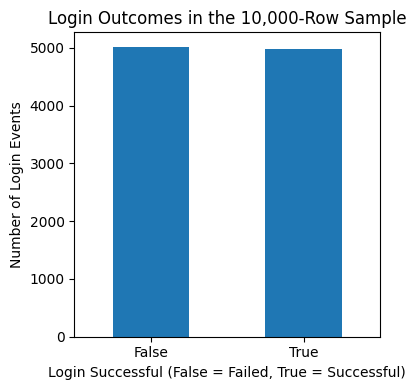

In [16]:
# Section 6: Login Outcome Distribution

outcome_counts = df["Login Successful"].value_counts(dropna=False)

outcome_percent = (
    df["Login Successful"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

outcome_summary = pd.DataFrame({
    "count": outcome_counts,
    "percentage": outcome_percent,
})

display(outcome_summary)

ax = outcome_counts.plot(
    kind="bar",
    rot=0,
    figsize=(4, 4)
)

ax.set_title("Login Outcomes in the 10,000-Row Sample")
ax.set_xlabel("Login Successful (False = Failed, True = Successful)")
ax.set_ylabel("Number of Login Events")

plt.tight_layout()
plt.show()

### Interpretation

Successful and failed login attempts are nearly balanced, at 49.82% and 50.18%, respectively. However, failed logins do not necessarily indicate malicious activity, and these results represent only the 10,000-row sample.

## 7 - Account-Takeover Label Distribution

We will understand how many events are labelled as account takeover in the sample. This is important because rare labels can make model evaluation difficult.

### Method
Inspect counts and percentages for `Is Account Takeover`. This column is a label, not a feature to use as model input.

,count,percentage
Is Account Takeover,,
False,10000,100.0


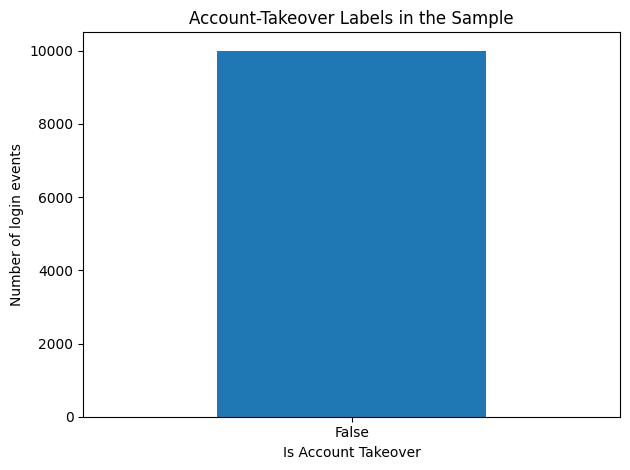

In [17]:
ato_counts = df["Is Account Takeover"].value_counts(dropna=False)
ato_percent = (
    df["Is Account Takeover"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(3)
)

ato_summary = pd.DataFrame({
    "count": ato_counts,
    "percentage": ato_percent,
})
display(ato_summary)

ax = ato_counts.plot(kind="bar", rot=0)
ax.set_title("Account-Takeover Labels in the Sample")
ax.set_xlabel("Is Account Takeover")
ax.set_ylabel("Number of login events")
plt.tight_layout()
plt.show()

### Interpretation

All 10,000 rows in the sample are labelled False, with no account-takeover cases. However, the full dataset contains only 141 positive cases, highlighting a severe class imbalance. The sample alone is therefore insufficient for evaluating ATO detection.

## 8 - Login Activity Over Time

ログインのタイムスタンプを使って、時間帯や日付によるログイン件数の変化を調べます。これは、将来的に「普段とは異なる時間にログインするユーザー」を検出するための基礎になります。

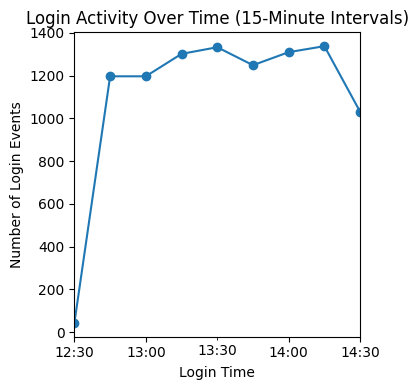

In [23]:
# Section 8: Login Activity Over Time

hourly_logins = (
    df.set_index("Login Timestamp")
      .resample("15min")
      .size()
)

ax = hourly_logins.plot(figsize=(4, 4), marker="o")
ax.set_title("Login Activity Over Time (15-Minute Intervals)")
ax.set_xlabel("Login Time")
ax.set_ylabel("Number of Login Events")

plt.tight_layout()
plt.show()

### Interpretation

Login activity increases sharply between 12:30 and 12:45, remains relatively high, and declines slightly toward 14:30. These fluctuations highlight short-term variations in login traffic but do not necessarily indicate malicious activity.

The 10 000 sample covers approximately two hours on a single day, limiting the ability to identify daily or long-term behavioural patterns. Further analysis using a broader time range is needed to establish normal login behaviour and detect potential anomalies.

## 9 - Country and Device-Type Overview

Describe the most common country and device categories in the sample. These variables may later help define user baselines, but their distributions alone do not prove suspicious activity.

Calculate frequency tables and visualise the most frequent categories.


### Country Distribution


,count,percentage
Country,,
NO,5091,50.91
US,2040,20.40
PL,604,6.04
BR,569,5.69
IN,232,2.32
UA,225,2.25
DE,168,1.68
AU,158,1.58
GB,112,1.12


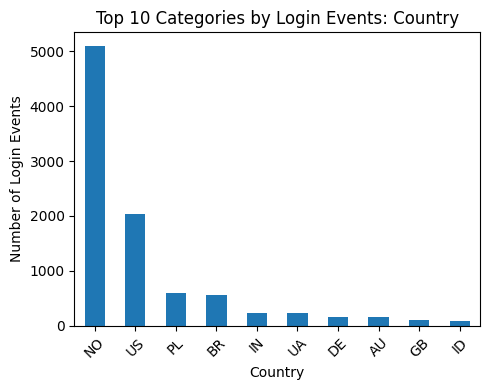


### Device Type Distribution


,count,percentage
Device Type,,
mobile,6616,66.16
desktop,3100,31.00
tablet,281,2.81
unknown,2,0.02
bot,1,0.01


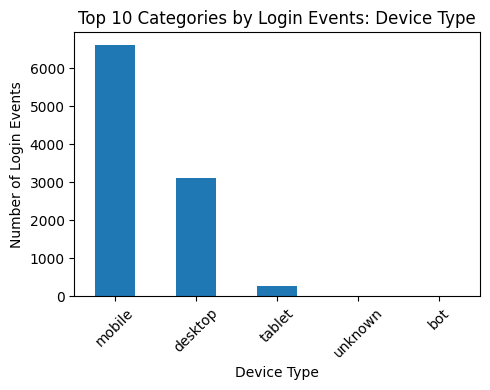

In [26]:
# Section 9: Country and Device-Type Overview

for column in ["Country", "Device Type"]:
    print(f"\n### {column} Distribution")

    counts = df[column].value_counts(dropna=False)
    summary = pd.DataFrame({
        "count": counts,
        "percentage": (counts / len(df) * 100).round(2)
    })

    display(summary.head(15))

    plot_counts = counts.head(10)

    ax = plot_counts.plot(kind="bar", rot=45, figsize=(5, 4))
    ax.set_title(f"Top 10 Categories by Login Events: {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Login Events")
    plt.tight_layout()
    plt.show()

### Interpretation — Country Distribution

Norway (`NO`) accounts for 50.91% of login events, followed by the United States (`US`) at 20.40%. This distribution shows that login activity is concentrated in a small number of country categories. However, `NO` may represent an unknown or unavailable country value rather than confirmed activity from Norway, so its meaning should be verified before drawing conclusions. Country information may help identify unusual login locations when compared with each user's historical behaviour.

### Interpretation — Device Type Distribution

Mobile devices account for the majority of login events (66.16%), followed by desktops (31.00%). Tablets represent only 2.81% of the sample, while unknown and bot categories are rare. Device type may help identify unusual login behaviour when compared with a user's typical activity.

## 10 - First User-Level Behaviour Check

Check whether the sample contains repeated events per user and establish a baseline for future time-based analysis.

Count login events per user and summarise the distribution. This is descriptive only; a high count may reflect a frequent legitimate user.

Unique users in sample: 4743


,login_events
count,4743.000000
mean,2.108370
std,50.376382
min,1.000000
50%,1.000000
75%,1.000000
90%,2.000000
95%,3.000000
99%,6.000000
max,3470.000000


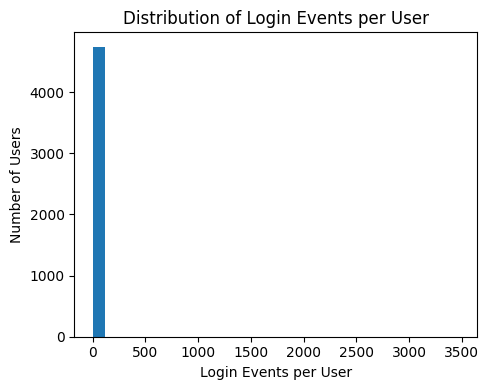

In [29]:
# Section 10: First User-Level Behaviour Check

events_per_user = (
    df.groupby("User ID")
      .size()
      .rename("login_events")
)

print("Unique users in sample:", df["User ID"].nunique())

display(
    events_per_user.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame()
)

ax = events_per_user.plot(
    kind="hist",
    bins=30,
    figsize=(5, 4)
)

ax.set_title("Distribution of Login Events per User")
ax.set_xlabel("Login Events per User")
ax.set_ylabel("Number of Users")

plt.tight_layout()
plt.show()

### Interpretation

Most users have only one login event in the sample: the median and 75th percentile are both 1. However, the mean is 2.11, and the maximum reaches 3,470 events, indicating a highly right-skewed distribution. These unusually high counts may reflect concentrated user activity or sampling effects and require further investigation. Since the analysis uses only 10,000 rows, these counts do not represent users' total login activity across the full dataset.

## 11 - Key Findings and Next Steps

### Key Findings

1. **Data quality:** The selected six columns contain no missing values, and no exact duplicate rows were found in the 10,000-row sample.
2. **Login outcomes:** 49.82% of login attempts were successful and 50.18% were unsuccessful.
3. **Account-takeover labels:** The sample contains no positive labels. A full-dataset scan identified 141 positive cases among 31,269,264 records, highlighting an extreme class imbalance.
4. **Country and device distributions:** `NO` is the most frequent country code (50.91%), followed by `US` (20.40%). Mobile is the most common device type (66.16%), followed by desktop (31.00%). The meaning of `NO` should be verified before interpreting it as a geographic location.
5. **User activity:** The sample contains 4,743 unique users. The median number of login events per user is 1, while the maximum is 3,470. This highly right-skewed distribution warrants further investigation.

## Business Interpretation

This exploratory analysis identifies useful features for investigating potentially anomalous login behaviour, including login outcomes, country, device type, timestamps, and user-level activity. However, these features alone cannot establish whether an account takeover has occurred. Unusual behaviour should be treated as a risk signal rather than definitive evidence of an attack.

## Next Steps

The next notebook, `02_rule_based_detection.ipynb`, will implement transparent baseline detection rules, such as repeated failed login attempts within a defined time window and changes in a user's observed country or device.

The rules will be evaluated against the available account-takeover labels. The target label must not be used as an input feature, and potential false positives and limitations will be discussed.

## Limitations

- The initial exploratory analysis uses only the first 10,000 rows, which may not represent the full dataset.
- The dataset is synthetic and may not reflect real-world login behaviour.
- Country and device attributes may contain ambiguous or imperfect values.
- The extreme class imbalance makes model evaluation challenging.
- Future validation should consider chronological or user-based splits to reduce data leakage.



## 12 - Dataset Citation and References

**Dataset:** Das et al., *Login Data Set for Risk-Based Authentication (RBA)*, Kaggle.  
https://www.kaggle.com/datasets/dasgroup/rba-dataset

**Associated paper:** Wiefling et al. (2022), “Pump Up Password Security! Evaluating and Enhancing Risk-Based Authentication on a Real-World Large-Scale Online Service,” *ACM Transactions on Privacy and Security*.  
https://doi.org/10.1145/3546069

**Dataset license:** CC BY 4.0, as indicated in the dataset information. Provide appropriate attribution when using or sharing work based on the dataset.